In [1]:

from pathlib import Path
import pandas as pd
import re

PROJECT_DIR = Path(r"C:\Users\S_Gayathri\skill-gap-analyzer")
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

resumes = pd.read_csv(
    PROCESSED_DIR / "cleaned_resumes.csv",
    low_memory=False
)

jobs = pd.read_csv(
    PROCESSED_DIR / "cleaned_job_postings_sample.csv",
    low_memory=False
)

print("Resumes loaded:", resumes.shape)
print("Job postings loaded:", jobs.shape)


Resumes loaded: (2484, 3)
Job postings loaded: (20000, 6)


In [2]:

SKILL_DICTIONARY = {
    "python": ["python", "python programming"],
    "sql": ["sql", "mysql", "postgresql", "sqlite"],
    "machine learning": ["machine learning", "scikit-learn", "sklearn"],
    "deep learning": ["deep learning"],
    "natural language processing": ["natural language processing", "nlp"],
    "generative ai": ["generative ai", "gen ai"],
    "large language models": ["large language model", "large language models", "llm", "llms"],
    "langchain": ["langchain"],
    "langgraph": ["langgraph"],
    "retrieval augmented generation": ["retrieval augmented generation", "rag"],
    "tensorflow": ["tensorflow"],
    "pytorch": ["pytorch"],
    "pandas": ["pandas"],
    "numpy": ["numpy"],
    "data analysis": ["data analysis", "data analytics"],
    "data visualization": ["data visualization", "matplotlib", "seaborn", "tableau", "power bi"],
    "flask": ["flask"],
    "fastapi": ["fastapi"],
    "django": ["django"],
    "streamlit": ["streamlit"],
    "scikit-learn": ["scikit-learn", "sklearn"],
    "computer vision": ["computer vision", "opencv"],
    "git": ["git", "github"],
    "docker": ["docker"],
    "aws": ["aws", "amazon web services"],
    "azure": ["microsoft azure", "azure"],
    "html": ["html"],
    "css": ["css"],
    "javascript": ["javascript"],
    "java": ["java"],
    "c++": ["c++"],
    "excel": ["microsoft excel", "excel"],
    "statistics": ["statistics", "statistical analysis"],
    "data structures": ["data structures", "data structures and algorithms"],
    "transformers": ["transformer", "transformers", "hugging face", "huggingface"],
    "vector databases": ["vector database", "vector databases", "chromadb", "pinecone", "faiss"],
    "api development": ["rest api", "restful api", "api development"]
}

print("Number of skill categories:", len(SKILL_DICTIONARY))


Number of skill categories: 37


In [3]:

def extract_skills(text, skill_dictionary=SKILL_DICTIONARY):
    if pd.isna(text):
        return []

    text = str(text).lower()
    found_skills = []

    for skill, aliases in skill_dictionary.items():
        for alias in aliases:
            pattern = r"(?<!\w)" + re.escape(alias.lower()) + r"(?!\w)"

            if re.search(pattern, text):
                found_skills.append(skill)
                break

    return sorted(set(found_skills))


test_text = """
I have experience in Python, SQL, machine learning, NLP,
LangChain, Flask, and vector databases such as ChromaDB.
"""

print(extract_skills(test_text))


['flask', 'langchain', 'machine learning', 'natural language processing', 'python', 'sql', 'vector databases']


In [4]:

resumes["extracted_skills"] = resumes["clean_resume"].apply(extract_skills)

resumes["skill_count"] = resumes["extracted_skills"].apply(len)

display(
    resumes[["ID", "Category", "skill_count", "extracted_skills"]].head(10)
)

print("Resumes with at least one extracted skill:",
      (resumes["skill_count"] > 0).sum())

print("Resumes without a matched skill:",
      (resumes["skill_count"] == 0).sum())


,ID,Category,skill_count,extracted_skills
0,16852973,HR,2,"[data analysis, statistics]"
1,22323967,HR,0,[]
2,33176873,HR,1,[excel]
3,27018550,HR,1,[excel]
4,17812897,HR,1,[excel]
5,11592605,HR,1,[excel]
6,25824789,HR,0,[]
7,15375009,HR,0,[]
8,11847784,HR,1,[excel]
9,32896934,HR,0,[]


Resumes with at least one extracted skill: 1257
Resumes without a matched skill: 1227


In [5]:

jobs["extracted_skills"] = jobs["job_text"].apply(extract_skills)

jobs["skill_count"] = jobs["extracted_skills"].apply(len)

display(
    jobs[["job_id", "title", "skill_count", "extracted_skills"]].head(10)
)

print("Job postings with at least one extracted skill:",
      (jobs["skill_count"] > 0).sum())

print("Job postings without a matched skill:",
      (jobs["skill_count"] == 0).sum())


,job_id,title,skill_count,extracted_skills
0,921716,Marketing Coordinator,0,[]
1,1829192,Mental Health Therapist/Counselor,0,[]
2,10998357,Assitant Restaurant Manager,0,[]
3,23221523,Senior Elder Law / Trusts and Estates Associat...,0,[]
4,35982263,Service Technician,0,[]
5,91700727,Economic Development and Planning Intern,1,[data analysis]
6,103254301,Producer,0,[]
7,112576855,Building Engineer,0,[]
8,1218575,Respiratory Therapist,0,[]
9,2264355,Worship Leader,0,[]


Job postings with at least one extracted skill: 4710
Job postings without a matched skill: 15290


,Skill,Job Posting Count
0,excel,2626
1,sql,720
2,data analysis,709
3,python,605
4,aws,489
5,azure,406
6,statistics,396
7,java,352
8,data visualization,336
9,javascript,271


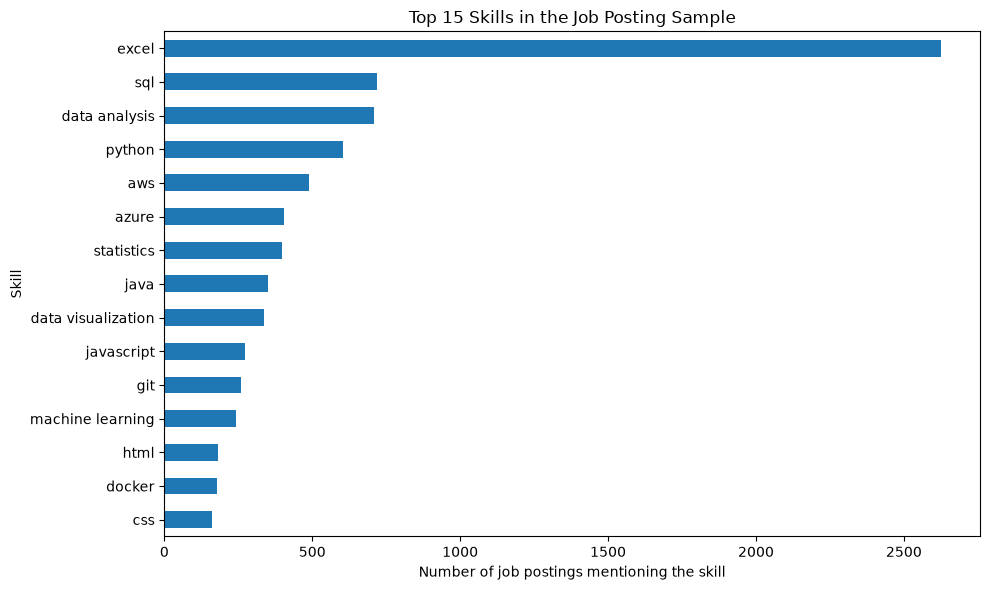

Chart saved: C:\Users\S_Gayathri\skill-gap-analyzer\reports\top_job_skills.png


In [6]:

from collections import Counter
import matplotlib.pyplot as plt

job_skill_counts = Counter(
    skill
    for skills in jobs["extracted_skills"]
    for skill in skills
)

top_job_skills = pd.Series(job_skill_counts).sort_values(
    ascending=False
).head(15)

display(
    top_job_skills.rename_axis("Skill")
    .reset_index(name="Job Posting Count")
)

if not top_job_skills.empty:
    top_job_skills.sort_values().plot(kind="barh", figsize=(10, 6))
    plt.title("Top 15 Skills in the Job Posting Sample")
    plt.xlabel("Number of job postings mentioning the skill")
    plt.ylabel("Skill")
    plt.tight_layout()

    chart_path = REPORTS_DIR / "top_job_skills.png"
    plt.savefig(chart_path, dpi=150, bbox_inches="tight")
    plt.show()

    print("Chart saved:", chart_path)
else:
    print("No skills matched. Review the skill dictionary and job text.")


In [7]:

import json

resumes["extracted_skills_json"] = resumes["extracted_skills"].apply(
    json.dumps
)

jobs["extracted_skills_json"] = jobs["extracted_skills"].apply(
    json.dumps
)

resumes[[
    "ID", "Category", "clean_resume",
    "extracted_skills_json", "skill_count"
]].to_csv(
    PROCESSED_DIR / "resumes_with_skills.csv",
    index=False
)

jobs[[
    "job_id", "company_name", "title",
    "job_text", "extracted_skills_json", "skill_count"
]].to_csv(
    PROCESSED_DIR / "jobs_with_skills.csv",
    index=False
)

print("Skill extraction completed successfully!")
print("Saved:", PROCESSED_DIR / "resumes_with_skills.csv")
print("Saved:", PROCESSED_DIR / "jobs_with_skills.csv")


Skill extraction completed successfully!
Saved: C:\Users\S_Gayathri\skill-gap-analyzer\data\processed\resumes_with_skills.csv
Saved: C:\Users\S_Gayathri\skill-gap-analyzer\data\processed\jobs_with_skills.csv
